# 12 — Analisis Tambahan Pasca-Evaluasi

Notebook ini **tidak melatih model apa pun**: seluruhnya membaca prediksi dan history yang sudah tersimpan. Isi:

1. **Loss curve** semua DL × setup × horizon + diagnosis terhadap *model nol* (apakah model belajar, hanya menemukan rata-rata, atau menghafal);
2. **Stabilitas** keunggulan terhadap Drift antar-**blok waktu** dan antar-**rezim volatilitas**;
3. **MSE return bergulir** relatif terhadap Drift untuk tiga model wakil;
4. **Diagnostik galat** (histogram, QQ, ACF) tiga model wakil;
5. **Feature importance** bawaan 10 model ML (porsi per variabel);
6. **Perbaikan MAE terhadap Drift** sepanjang horizon.

Seluruh pengelompokan (blok, rezim) memakai informasi yang tersedia **di hari origin**; batas rezim dihitung dari **train** saja. Pemilihan tiga model wakil bersifat deskriptif pasca-evaluasi (lihat notebook 09).

In [1]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK)
from src import analysis as A, plots as P, stats as S
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, RUNS, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    """Simpan figur (PNG + PDF) ke outputs/figures lalu tampilkan."""
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from src.explain import group_of, GROUP_LABEL
from src.pipeline import dl_target_baselines
from src.config import SEQ_LEN, N_BLOCKS

wakil = A.load_wakil(RES)
reps3 = [wakil['dpformer'], wakil['dl'], wakil['ml']]
tabel = pd.read_csv(os.path.join(RES, 'tabel_hasil_final.csv'))
urut = pd.read_csv(os.path.join(RES, 'ringkasan_model.csv')).model.tolist()     # urutan model menurut ranking
H_SHOW = 20 if 20 in HORIZONS else max(HORIZONS)
fr = {h: A.drift_frame(p, h) for h in HORIZONS}
print('Wakil:', wakil)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
Wakil: {'dpformer': 'dpformer', 'dl': 'gru_att', 'ml': 'adaboost', 'kriteria': 'peringkat rata-rata MAE dalam kelompok (2 setup x horizon); seri: rata-rata pct_vs_drift; DPformer tetap', 'protocol': 'v9-21model-dpformer-bao-aligned-honest-mossa-shap-leakage-safe-embargo'}


## 1. Loss curve dan diagnosis

Target DL di-*z-score* pada train, sehingga **model nol** (selalu memprediksi rata-rata train) memiliki MSE train = 1 (garis putus-putus biru). Di validasi, model nol tidak harus bernilai 1 karena rezim validasi berbeda dari train (garis putus-putus merah). Skill = 1 − loss / loss model nol.

- **Belajar**: epoch terbaik mengalahkan model nol ≥ 2%.
- **Tanpa sinyal**: epoch terbaik ≈ model nol (±2%) — model hanya menemukan rata-rata. Ini hasil yang *wajar* untuk return emas yang hampir efisien.
- **Di bawah model nol**: bahkan epoch terbaik lebih buruk daripada model nol di validasi.
- **Overfit** (atribut terpisah): setelah epoch terbaik loss validasi naik > 5% dari model nol sementara loss train masih turun. Bobot yang dipakai untuk uji adalah **epoch terbaik** (`restore_best_weights`), jadi overfit ini menjelaskan *bentuk kurva*, bukan model yang diuji.

,n_run,belajar,tanpa_sinyal,di_bawah_nol,overfit,epoch_terbaik_median
setup,,,,,,
multivariat,55,4,25,26,33,2.0
univariat,55,0,43,12,6,3.0


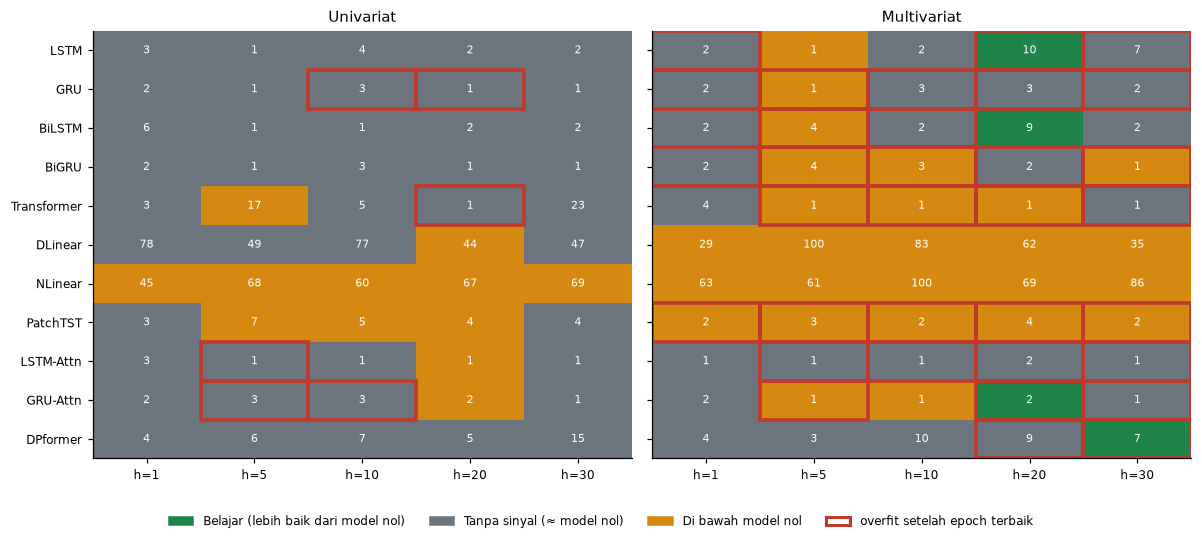

In [2]:
diag = pd.read_csv(os.path.join(RES, 'diagnosis_loss.csv'))
ring = (diag.groupby('setup')
        .agg(n_run=('model', 'size'), belajar=('kelas', lambda x: int((x == 'BELAJAR').sum())),
             tanpa_sinyal=('kelas', lambda x: int((x == 'TANPA_SINYAL').sum())),
             di_bawah_nol=('kelas', lambda x: int((x == 'DI_BAWAH_NOL').sum())),
             overfit=('overfit', 'sum'), epoch_terbaik_median=('best_epoch', 'median')))
display(ring)
fig = P.fig_loss_classes(diag, HORIZONS, DL_MODELS)
simpan(fig, 'fig_loss_kelas')

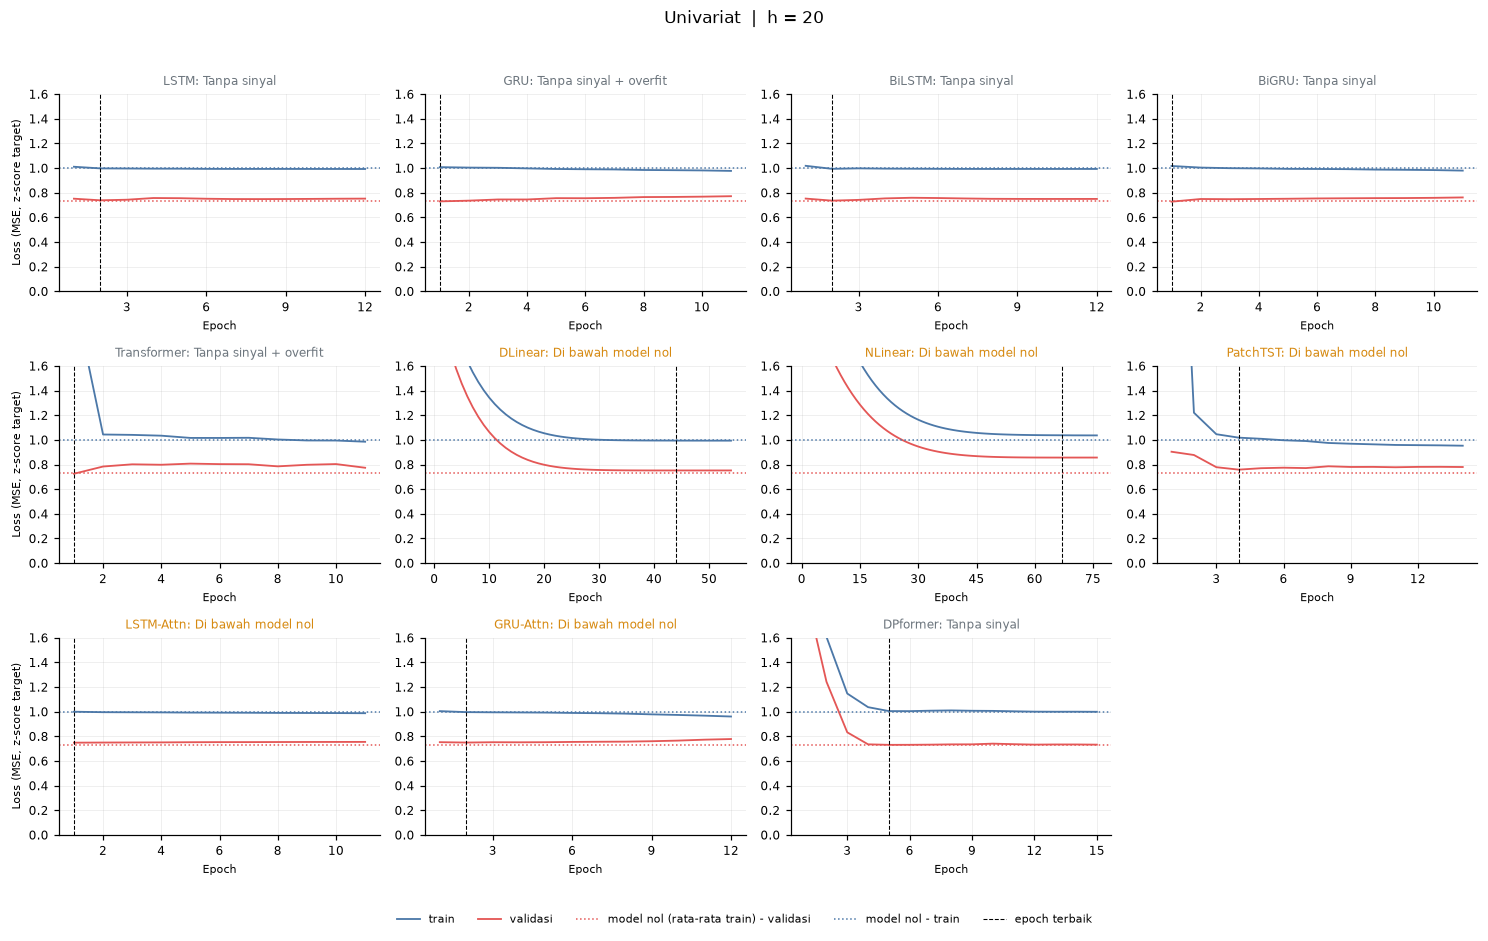

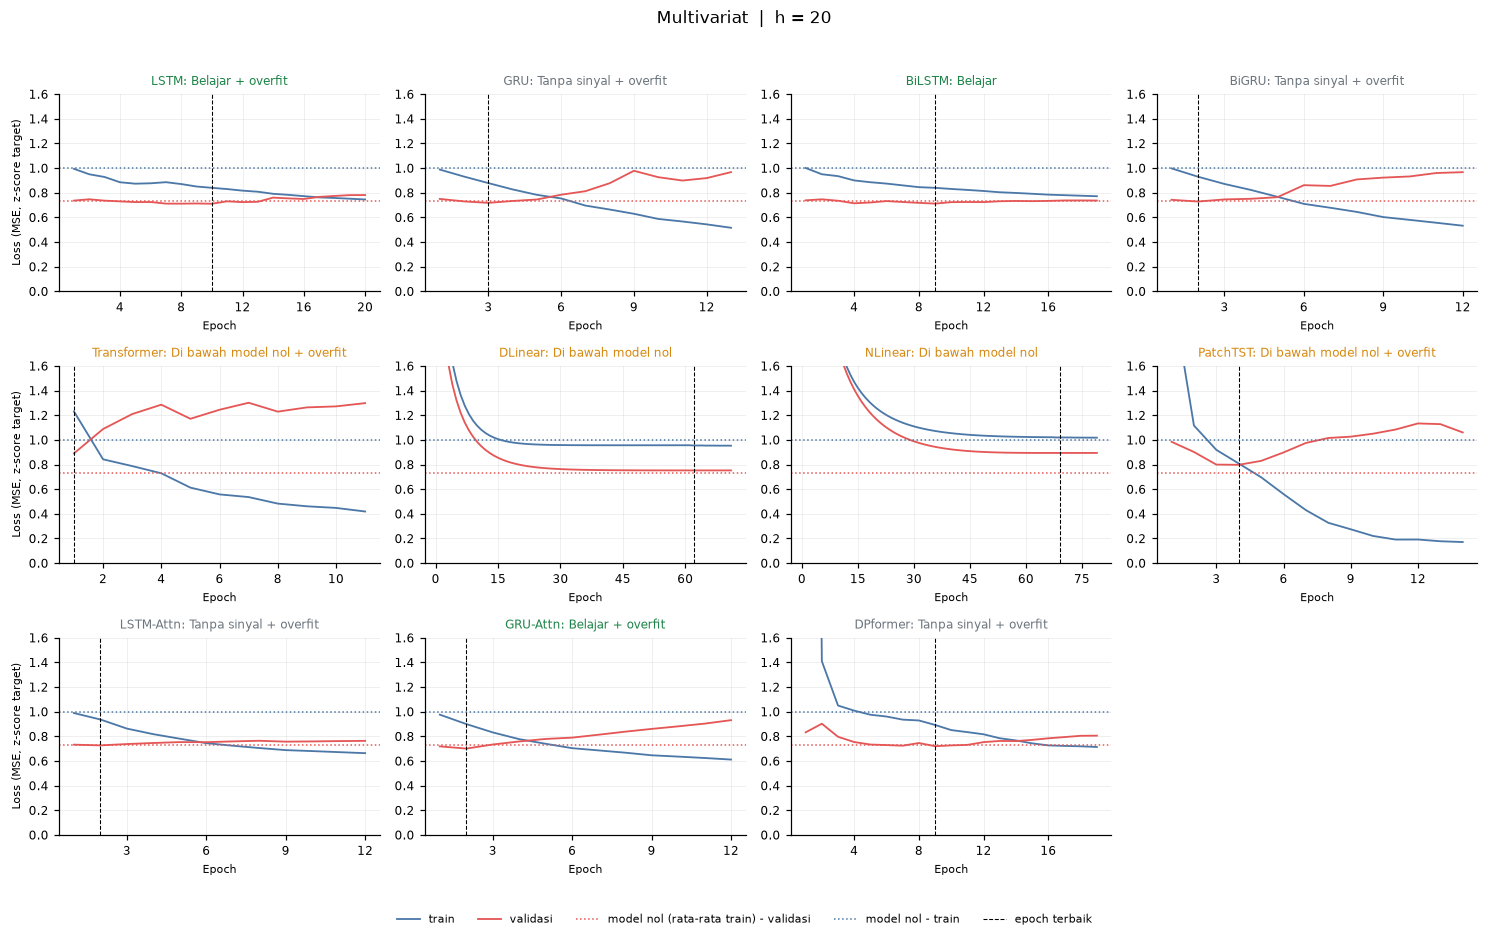

Figur loss curve tersimpan: fig_loss_<setup>_h<h> untuk semua horizon.


In [3]:
for h in HORIZONS:
    nulls = dl_target_baselines(p, h, seq_len=SEQ_LEN)
    for setup in SETUPS:
        hist = {}
        for m in DL_MODELS:
            f = os.path.join(RUNS, f'{setup}_{m}_h{h}_history.json')
            if os.path.exists(f):
                with open(f, encoding='utf-8') as fh:
                    hist[m] = json.load(fh)
        fig = P.fig_loss_grid(hist, diag, nulls, setup, h, DL_MODELS)
        if h == H_SHOW:
            simpan(fig, f'fig_loss_{setup}_h{h}')          # ditampilkan; horizon lain hanya disimpan
        else:
            P.save_fig(fig, f'fig_loss_{setup}_h{h}', FIGS)
            plt.close(fig)
print('Figur loss curve tersimpan: fig_loss_<setup>_h<h> untuk semua horizon.')

### Cara membaca loss curve (jujur)

- Return harian emas hampir derau. Pada data seperti ini kurva yang **sehat** adalah kurva yang turun sedikit lalu mendatar *di sekitar model nol*; kurva yang turun jauh di bawah 1 pada train tetapi tidak diikuti validasi berarti model **menghafal** derau train.
- DL **multivariat** (8 kanal masukan) menghafal lebih cepat daripada univariat (epoch terbaik sangat dini; lihat `epoch_terbaik_median` pada tabel di atas); DLinear/NLinear berkapasitas kecil sehingga konvergen lambat dan mendatar di atas model nol.
- Validasi (2021-07..2023-03) adalah periode **tenang**, uji (2023-03..2026-08) periode **volatil** dengan reli: loss validasi tidak sebanding langsung dengan loss train maupun loss uji. Ini artefak rezim, bukan bug.
- Memaksa semua kurva "bagus" hanya mungkin dengan mengubah data/protokol (mis. memilih epoch dengan melihat uji) — itu kebocoran, bukan perbaikan. Yang dapat dilaporkan dengan jujur: kelas diagnosis di atas, epoch terbaik, dan bahwa bobot uji = epoch validasi terbaik.
- Pada hasil saat paket ini disusun, gambaran ini konsisten dengan notebook 10: tidak ada model yang secara meyakinkan mengalahkan Drift pada return.

## 2. Stabilitas antar-blok waktu dan rezim volatilitas

Periode uji dibagi menjadi 4 blok sama panjang. Untuk tiap model: rasio MSE-return model / Drift per blok (**< 1 = lebih baik dari Drift**). Rezim volatilitas: tenang / sedang / tinggi menurut volatilitas realisasi 20 hari di hari origin, dengan batas (tercile) dari **train**.

In [4]:
blk, rez = A.block_regime_tables(RES, p, SETUPS, ALL_MODELS, HORIZONS, N_BLOCKS)
blk.to_csv(os.path.join(RES, 'stabilitas_blok.csv'), index=False)
rez.to_csv(os.path.join(RES, 'stabilitas_rezim.csv'), index=False)

b0 = blk[(blk.setup == SETUPS[0]) & (blk.model == blk.model.iloc[0]) & (blk.horizon == H_SHOW)][['blok', 'mulai', 'akhir', 'n']]
print(f'Blok waktu uji (h={H_SHOW}):')
display(b0)

med = blk.groupby(['setup', 'horizon', 'blok']).rel_mse.median().unstack('blok')
nb = blk.assign(lebih_baik=blk.rel_mse < 1).groupby(['setup', 'horizon', 'blok']).lebih_baik.sum().unstack('blok')
print('Median rasio MSE-return (21 model) per blok  (<1 = lebih baik dari Drift):')
display(med.round(3))
print('Jumlah model (dari 21) yang lebih baik dari Drift per blok:')
display(nb.astype(int))

Blok waktu uji (h=20):


,blok,mulai,akhir,n
252,1,2023-04-17,2024-02-12,216
253,2,2024-02-13,2024-12-09,215
254,3,2024-12-10,2025-10-06,215
255,4,2025-10-07,2026-08-03,215


Median rasio MSE-return (21 model) per blok  (<1 = lebih baik dari Drift):


blok                     1      2      3      4
setup       horizon                            
multivariat 1        1.011  1.024  1.029  1.012
            5        1.041  1.014  0.942  1.028
            10       1.038  1.027  0.917  1.001
            20       1.201  1.015  0.993  0.999
            30       1.286  0.994  0.995  1.001
univariat   1        1.008  1.008  1.018  0.998
            5        1.022  1.012  0.983  1.014
            10       1.051  0.997  0.978  0.997
            20       1.089  0.979  0.987  0.971
            30       1.130  0.992  1.004  0.984

Jumlah model (dari 21) yang lebih baik dari Drift per blok:


blok                 1   2   3   4
setup       horizon               
multivariat 1        7   5   6   6
            5        0   6  20   2
            10       1   4  20  10
            20       1   9  13  11
            30       0  11  11  10
univariat   1        6   4   5  11
            5        3   5  16   7
            10       2  14  20  17
            20       5  17  16  17
            30       1  14   8  18

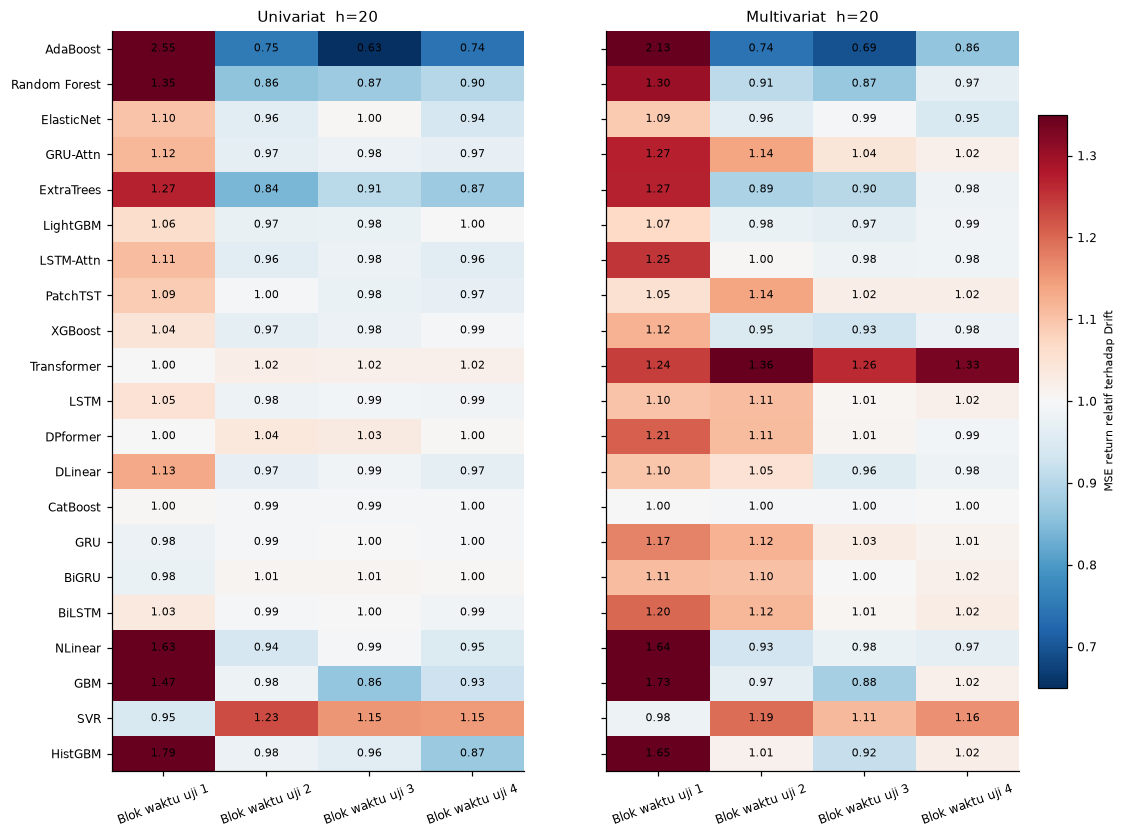

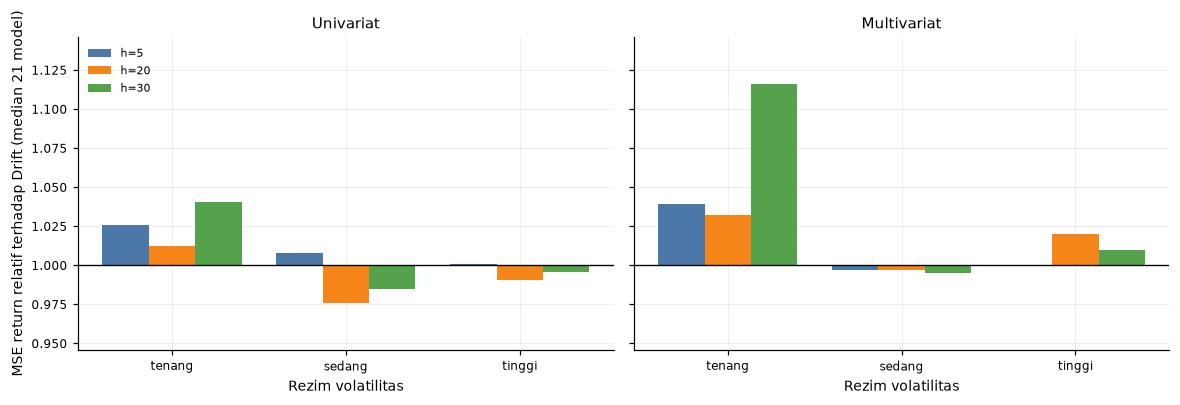

Median rasio MSE per rezim volatilitas (21 model):


rezim                tenang  sedang  tinggi
setup       horizon                        
multivariat 1         1.137   1.017   1.016
            5         1.039   0.997   1.000
            10        0.995   1.003   0.980
            20        1.032   0.997   1.020
            30        1.116   0.995   1.010
univariat   1         1.066   1.016   1.002
            5         1.026   1.008   1.001
            10        1.010   1.006   0.992
            20        1.013   0.976   0.990
            30        1.041   0.985   0.996

In [5]:
fig = P.fig_block_heatmap(blk, urut, list(range(1, N_BLOCKS + 1)), SETUPS, h=H_SHOW)
simpan(fig, f'fig_stabilitas_blok_h{H_SHOW}')
hs_reg = [h for h in (5, 20, 30) if h in HORIZONS]
fig = P.fig_regime_bars(rez, SETUPS, horizons=tuple(hs_reg))
simpan(fig, 'fig_stabilitas_rezim')
print('Median rasio MSE per rezim volatilitas (21 model):')
display(rez.groupby(['setup', 'horizon', 'rezim']).rel_mse.median().unstack('rezim').rename(columns={0: 'tenang', 1: 'sedang', 2: 'tinggi'}).round(3))

**Cara membaca.** Keunggulan terhadap Drift yang hanya muncul pada sebagian blok/rezim (mis. saat reli) **bukan** keunggulan yang stabil: pada periode datar model cenderung kalah dari Drift karena menambah varians prediksi tanpa sinyal. Notebook 16 (walk-forward) menguji hal yang sama pada enam periode uji berbeda.

## 3. MSE return bergulir relatif terhadap Drift

Rasio MSE-return model / Drift pada jendela bergulir 120 hari origin untuk tiga model wakil (garis putus-putus = 1,0; area abu-abu = volatilitas 20 hari).

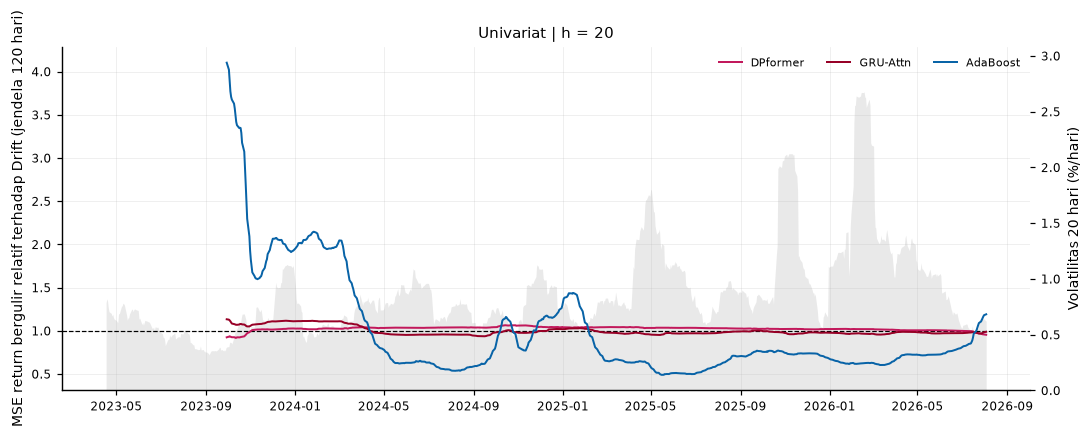

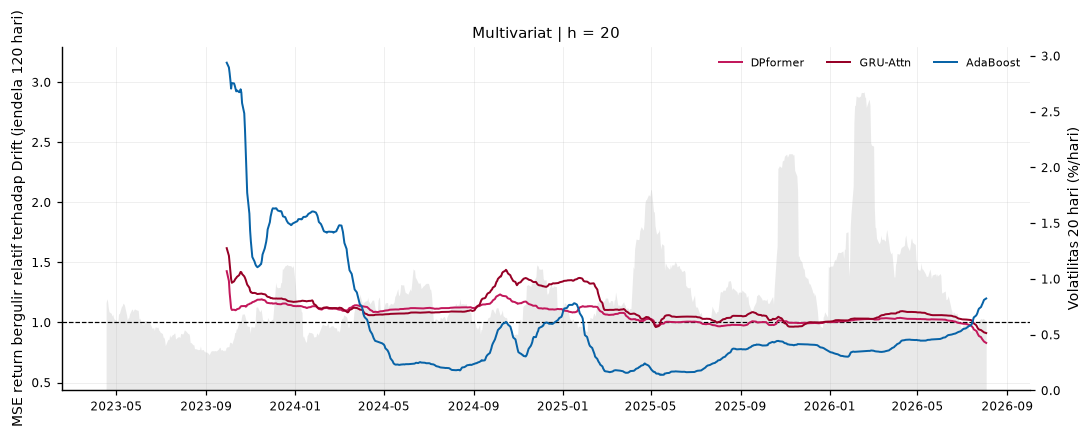

In [6]:
vol = A.vol_causal(p, 20)
SER = {}
for setup in SETUPS:
    ser = {}
    for m in reps3:
        d = A.attach(A.read_pred(RES, setup, m, H_SHOW), fr[H_SHOW])
        d['r_drift'] = fr[H_SHOW].r_pred.reindex(d.index).values
        ser[m] = d
    SER[setup] = ser
    fig = P.fig_rolling_rel(ser, vol=vol, window=120)
    fig.axes[0].set_title(f'{"Univariat" if setup == "univariat" else "Multivariat"} | h = {H_SHOW}')
    simpan(fig, f'fig_mse_bergulir_{setup}_h{H_SHOW}')

## 4. Diagnostik galat tiga model wakil

Histogram dan QQ galat return, serta ACF. Galat peramalan *h-langkah* pada origin harian bertumpang-tindih sehingga **ACF wajar tinggi hingga lag h−1** (area kuning); pita ±1,96/√n hanya berlaku untuk lag ≥ h.

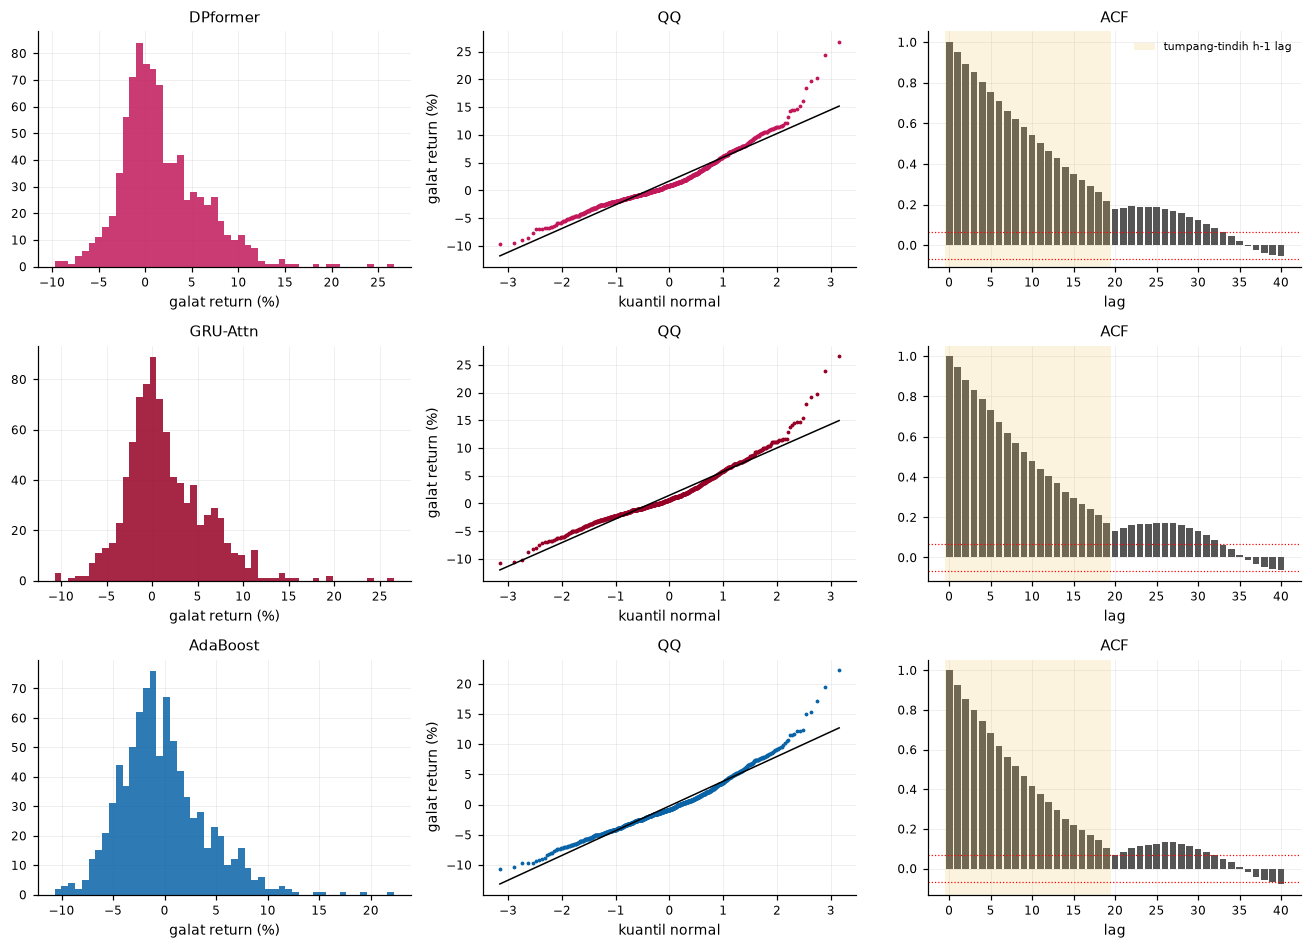

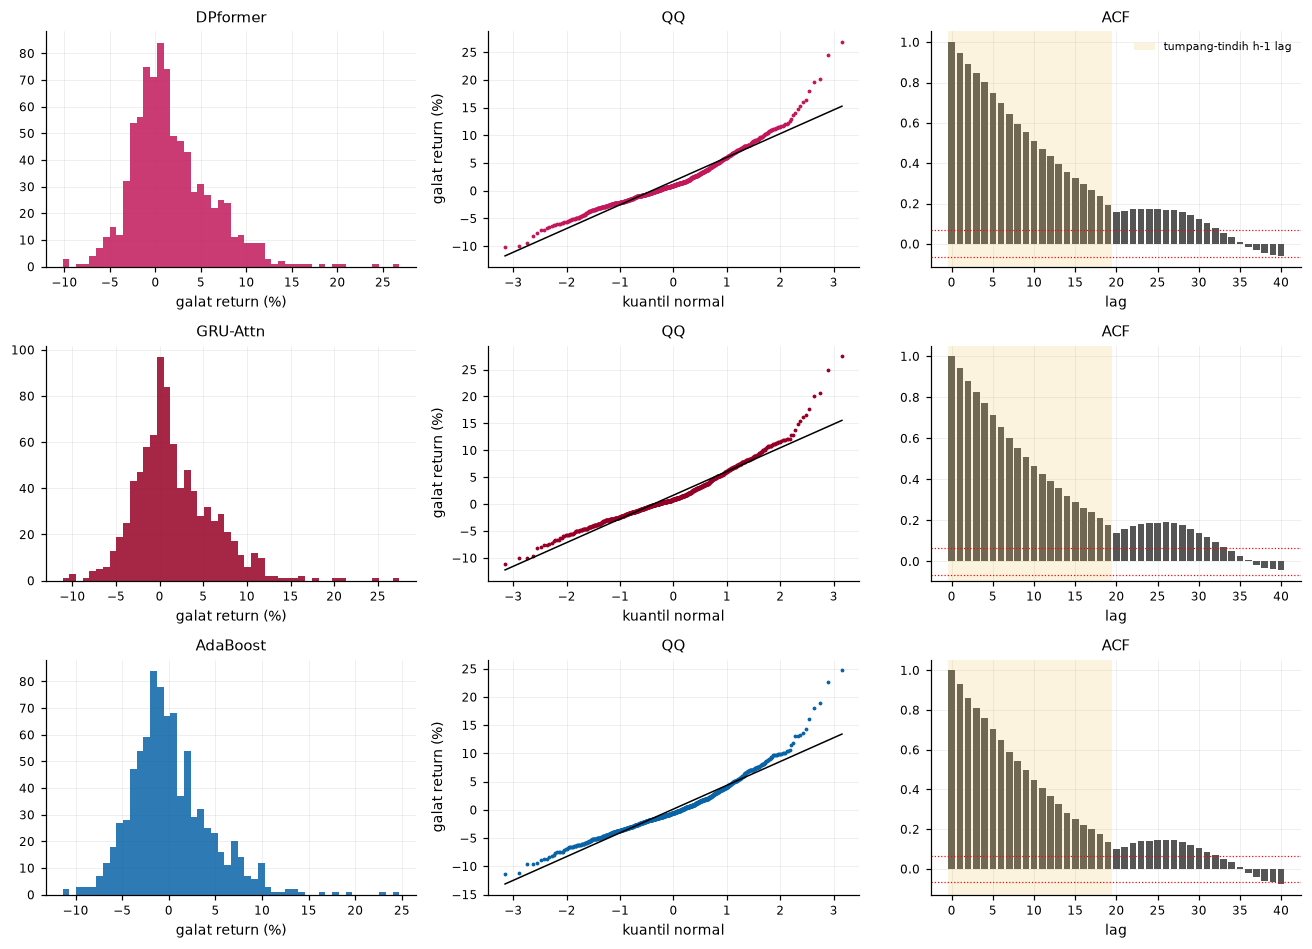

Bias return (aktual - prediksi); positif = model cenderung meramal terlalu rendah:


,setup,model,rata2_galat_return_%,sd_galat_%,rata2_return_aktual_%,rata2_return_prediksi_%
0,univariat,dpformer,1.692,4.382,2.18,0.488
1,univariat,gru_att,1.485,4.364,2.18,0.695
2,univariat,adaboost,-0.230,4.163,2.18,2.410
3,multivariat,dpformer,1.749,4.384,2.18,0.430
4,multivariat,gru_att,1.663,4.494,2.18,0.516
5,multivariat,adaboost,0.144,4.306,2.18,2.035


In [7]:
bias = []
for setup in SETUPS:
    fig = P.fig_resid_diag(SER[setup], nlags=40, h=H_SHOW)
    simpan(fig, f'fig_galat_{setup}_h{H_SHOW}')
    for m, d in SER[setup].items():
        e = (d.r_true - d.r_pred).values
        bias.append({'setup': setup, 'model': m, 'rata2_galat_return_%': 100 * e.mean(), 'sd_galat_%': 100 * e.std(),
                     'rata2_return_aktual_%': 100 * d.r_true.mean(), 'rata2_return_prediksi_%': 100 * d.r_pred.mean()})
print('Bias return (aktual - prediksi); positif = model cenderung meramal terlalu rendah:')
display(pd.DataFrame(bias).round(3))

**Cara membaca.** Rata-rata galat positif pada periode uji menunjukkan model (dilatih pada periode dengan tren naik lebih lemah) **meramal terlalu rendah** selama reli. Ini sifat rezim uji, bukan indikasi kebocoran.

## 5. Feature importance bawaan model ML

Porsi importance (dinormalkan per model) per **variabel**: seluruh fitur turunan Antam (lag, rolling) digabung menjadi satu kelompok, indikator makro masing-masing satu kelompok. Skala importance berbeda antarfamili (gain, impurity, |koefisien|): bandingkan **pola**, bukan angka mutlak. SHAP (notebook 11) adalah penjelasan yang lebih dapat dibandingkan.

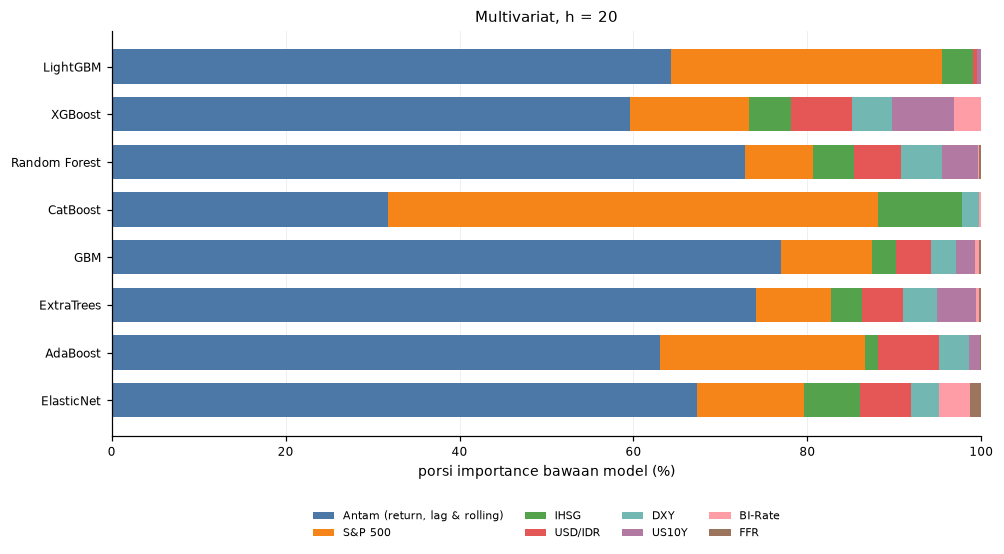

,emas,dxy,sp500,usd_idr,ihsg,us10yr,ffr,bi_rate
lightgbm,64.3,0.0,31.2,0.5,3.5,0.5,0.0,0.0
xgboost,59.6,4.5,13.7,7.0,4.9,7.2,0.0,3.1
rf,72.8,4.7,7.9,5.4,4.7,4.2,0.3,0.1
catboost,31.8,2.0,56.3,0.0,9.7,0.0,0.0,0.2
gbm,77.0,2.9,10.5,4.0,2.7,2.2,0.3,0.4
extra_trees,74.1,3.9,8.6,4.7,3.6,4.6,0.3,0.3
adaboost,63.1,3.4,23.5,7.1,1.5,1.4,0.1,0.0
elasticnet,67.3,3.3,12.3,5.9,6.4,0.0,1.2,3.6


In [8]:
rows = []
for m in ML_MODELS:
    f = os.path.join(RUNS, f'multivariat_{m}_h{H_SHOW}_fimp.csv')
    if not os.path.exists(f):
        continue
    fi = pd.read_csv(f, index_col=0).iloc[:, 0].abs()
    fi = fi / fi.sum()
    rows.append(fi.groupby([group_of(x) for x in fi.index]).sum().rename(m))
if rows:
    imp = pd.DataFrame(rows).fillna(0.0)
    imp = imp.reindex(columns=[g for g in GROUP_LABEL if g in imp.columns])
    imp.round(4).to_csv(os.path.join(RES, 'importance_ml_porsi_variabel.csv'))
    fig = P.fig_ml_importance(imp, title=f'Multivariat, h = {H_SHOW}')
    simpan(fig, f'fig_importance_ml_h{H_SHOW}')
    display((imp * 100).round(1))
else:
    print('Berkas *_fimp.csv belum ada (jalankan notebook 07).')

## 6. Perbaikan MAE terhadap Drift sepanjang horizon

Garis tipis abu-abu = 21 model, garis tebal hitam = median seluruh model, garis berwarna = tiga model wakil. **Positif = lebih baik dari Drift.**

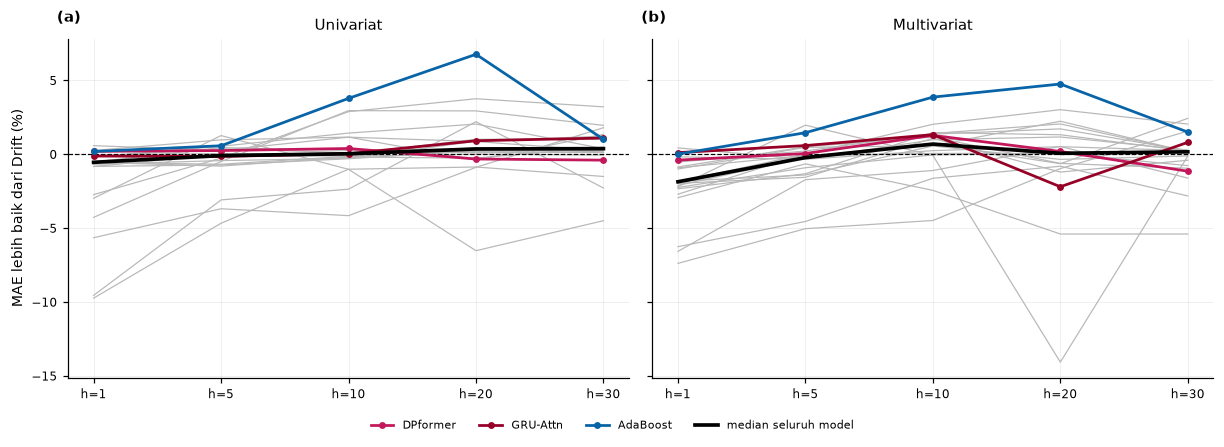

median  terbaik  terburuk
setup       horizon                           
multivariat 1         -1.86     0.43     -7.38
            5         -0.22     1.97     -5.03
            10         0.69     3.87     -4.48
            20         0.07     4.76    -14.06
            30         0.17     2.43     -5.39
univariat   1         -0.54     0.59     -9.74
            5         -0.09     1.27     -4.67
            10         0.04     3.78     -4.15
            20         0.36     6.77     -6.52
            30         0.38     3.21     -4.49

In [9]:
fig = P.fig_gain_vs_horizon(tabel, HORIZONS, highlight=reps3)
simpan(fig, 'fig_perbaikan_vs_horizon')
g = tabel.groupby(['setup', 'horizon']).pct_vs_drift.agg(median='median', terbaik='max', terburuk='min').round(2)
display(g)

### Ringkasan yang dapat dipakai di naskah

- Median seluruh model berada di sekitar 0% terhadap Drift pada semua horizon: **tidak ada keunggulan sistematis**; selisih beberapa persen pada MAE mudah muncul karena variasi sampel (cek DM/MCS di notebook 10).
- Keunggulan model individual (mis. AdaBoost pada h = 10/20) bergantung pada blok/rezim periode uji dan tidak dijadikan klaim umum.
- Loss curve menunjukkan DL pada return emas berada pada kelas *tanpa sinyal* atau *di bawah model nol* — konsisten dengan hipotesis pasar yang hampir efisien.